# Decision Tree V4

For V4, I wanted to compare entropy and Gini impurity to see if the splitting criterion would affect the Decision Tree results. I kept the same samples and the settings selected in V3.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task, split_train_val
from src.models.decision_tree import DecisionTreeClassifier

criteria = ["entropy", "gini"]
result_dir = project_root / "results" / "decision_tree"
v3_summary = pd.read_csv(result_dir / "decision_tree_v3_summary.csv")


I started by comparing entropy and Gini on the image dataset.

In [2]:
X, y, _, _ = load_task("image")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
image_X_train = X_train[:200]
image_y_train = y_train[:200]
image_X_val = X_val[:200]
image_y_val = y_val[:200]
assert image_X_train.shape == (200, 500)
assert image_X_val.shape == (200, 500)
v3_validation = pd.read_csv(result_dir / "decision_tree_v3_image_validation.csv")
v3_result = v3_summary.loc[(v3_summary["dataset"] == "image") & (v3_summary["max_depth"] == 2) & (v3_summary["min_samples"] == 1)].iloc[0]
assert v3_validation["validation_index"].tolist() == list(range(200))
assert v3_validation["actual_label"].tolist() == image_y_val.tolist()

image_rows = []
image_models = {}
image_validation_predictions = {}
for criterion in criteria:
    clf = DecisionTreeClassifier(max_depth=2, min_samples=1, criterion=criterion)
    print(f"Fitting image: depth=2, criterion={criterion}, 200 training samples, 500 features")
    start = perf_counter()
    clf.fit(image_X_train, image_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(image_X_train, image_y_train)
    start = perf_counter()
    y_pred = clf.predict(image_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, image_y_val)) / len(image_y_val)
    image_models[criterion] = clf
    image_validation_predictions[criterion] = y_pred
    if criterion == "entropy":
        assert training_accuracy == v3_result["training_accuracy"] == 0.095
        assert validation_accuracy == v3_result["validation_accuracy"] == 0.045
        assert y_pred == v3_validation["predicted_label"].tolist()
        print("Entropy reproduces selected V3 accuracies and all validation predictions exactly.")
    image_rows.append({
        "dataset": "image",
        "version": "V4",
        "criterion": criterion,
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(image_X_train),
        "validation_samples": len(image_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"criterion={criterion}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
image_summary = pd.DataFrame(image_rows)


Fitting image: depth=2, criterion=entropy, 200 training samples, 500 features
Entropy reproduces selected V3 accuracies and all validation predictions exactly.
criterion=entropy, training=9.50%, validation=4.50%
Fit time=3.299578 s, validation prediction time=0.001041 s
Fitting image: depth=2, criterion=gini, 200 training samples, 500 features
criterion=gini, training=7.50%, validation=2.00%
Fit time=3.480366 s, validation prediction time=0.001215 s


Then I repeated the same comparison with the sentiment dataset.

In [3]:
X, y, _, _ = load_task("sentiment")
X_train, X_val, y_train, y_val = split_train_val(X, y, val_fraction=0.2, seed=42)
sentiment_X_train = X_train[:200]
sentiment_y_train = y_train[:200]
sentiment_X_val = X_val[:200]
sentiment_y_val = y_val[:200]
assert sentiment_X_train.shape == (200, 768)
assert sentiment_X_val.shape == (200, 768)
v3_validation = pd.read_csv(result_dir / "decision_tree_v3_sentiment_validation.csv")
v3_result = v3_summary.loc[(v3_summary["dataset"] == "sentiment") & (v3_summary["max_depth"] == 3) & (v3_summary["min_samples"] == 1)].iloc[0]
assert v3_validation["validation_index"].tolist() == list(range(200))
assert v3_validation["actual_label"].tolist() == sentiment_y_val.tolist()

sentiment_rows = []
sentiment_models = {}
sentiment_validation_predictions = {}
for criterion in criteria:
    clf = DecisionTreeClassifier(max_depth=3, min_samples=1, criterion=criterion)
    print(f"Fitting sentiment: depth=3, criterion={criterion}, 200 training samples, 768 features")
    start = perf_counter()
    clf.fit(sentiment_X_train, sentiment_y_train)
    fit_time = perf_counter() - start
    training_accuracy = clf.score(sentiment_X_train, sentiment_y_train)
    start = perf_counter()
    y_pred = clf.predict(sentiment_X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(y_pred, sentiment_y_val)) / len(sentiment_y_val)
    sentiment_models[criterion] = clf
    sentiment_validation_predictions[criterion] = y_pred
    if criterion == "entropy":
        assert training_accuracy == v3_result["training_accuracy"] == 0.675
        assert validation_accuracy == v3_result["validation_accuracy"] == 0.45
        assert y_pred == v3_validation["predicted_label"].tolist()
        print("Entropy reproduces selected V3 accuracies and all validation predictions exactly.")
    sentiment_rows.append({
        "dataset": "sentiment",
        "version": "V4",
        "criterion": criterion,
        "max_depth": clf.max_depth,
        "min_samples": clf.min_samples,
        "normalized": False,
        "training_samples": len(sentiment_X_train),
        "validation_samples": len(sentiment_X_val),
        "training_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "fit_time_seconds": fit_time,
        "prediction_time_seconds": prediction_time,
    })
    print(f"criterion={criterion}, training={training_accuracy:.2%}, validation={validation_accuracy:.2%}")
    print(f"Fit time={fit_time:.6f} s, validation prediction time={prediction_time:.6f} s")
sentiment_summary = pd.DataFrame(sentiment_rows)


Fitting sentiment: depth=3, criterion=entropy, 200 training samples, 768 features
Entropy reproduces selected V3 accuracies and all validation predictions exactly.
criterion=entropy, training=67.50%, validation=45.00%
Fit time=20.565880 s, validation prediction time=0.000650 s
Fitting sentiment: depth=3, criterion=gini, 200 training samples, 768 features
criterion=gini, training=68.00%, validation=40.00%
Fit time=19.155465 s, validation prediction time=0.000682 s


I plotted the training and validation accuracies to compare the two criteria.

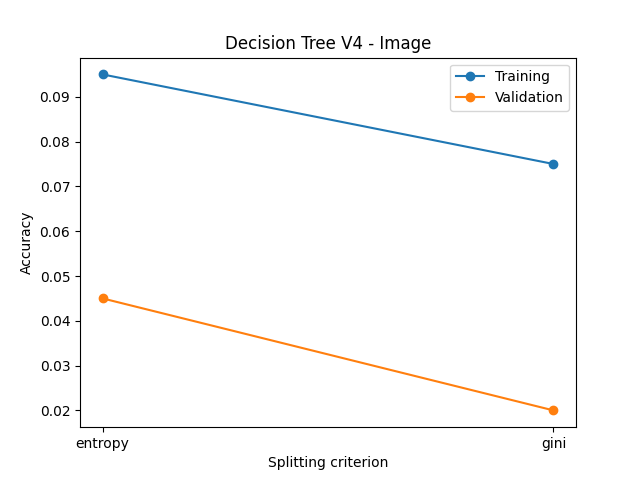

In [4]:
plt.figure()
plt.plot(criteria, image_summary["training_accuracy"], marker="o", label="Training")
plt.plot(criteria, image_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Splitting criterion")
plt.ylabel("Accuracy")
plt.title("Decision Tree V4 - Image")
plt.xticks(criteria)
plt.legend()
plt.savefig(result_dir / "decision_tree_v4_image_criterion.png")
plt.show()


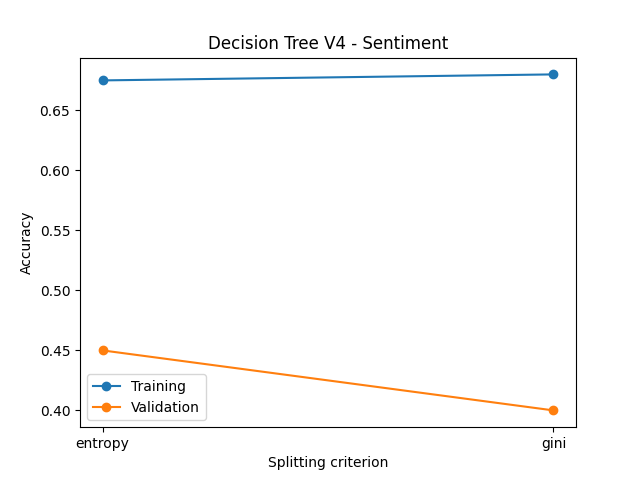

In [5]:
plt.figure()
plt.plot(criteria, sentiment_summary["training_accuracy"], marker="o", label="Training")
plt.plot(criteria, sentiment_summary["validation_accuracy"], marker="o", label="Validation")
plt.xlabel("Splitting criterion")
plt.ylabel("Accuracy")
plt.title("Decision Tree V4 - Sentiment")
plt.xticks(criteria)
plt.legend()
plt.savefig(result_dir / "decision_tree_v4_sentiment_criterion.png")
plt.show()


Finally, I compared the validation results to choose which criterion to keep for each dataset.

In [6]:
image_best_accuracy = -1
for row in image_rows:
    # Entropy is tested first, so it wins an accuracy tie.
    if row["validation_accuracy"] > image_best_accuracy:
        image_best_criterion = row["criterion"]
        image_best_accuracy = row["validation_accuracy"]
print(f"Image: selected criterion={image_best_criterion}, validation accuracy={image_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(image_y_val)),
    "actual_label": image_y_val,
    "predicted_label": image_validation_predictions[image_best_criterion],
}).to_csv(result_dir / "decision_tree_v4_image_validation.csv", index=False)

sentiment_best_accuracy = -1
for row in sentiment_rows:
    # Entropy is tested first, so it wins an accuracy tie.
    if row["validation_accuracy"] > sentiment_best_accuracy:
        sentiment_best_criterion = row["criterion"]
        sentiment_best_accuracy = row["validation_accuracy"]
print(f"Sentiment: selected criterion={sentiment_best_criterion}, validation accuracy={sentiment_best_accuracy:.2%}")
pd.DataFrame({
    "validation_index": range(len(sentiment_y_val)),
    "actual_label": sentiment_y_val,
    "predicted_label": sentiment_validation_predictions[sentiment_best_criterion],
}).to_csv(result_dir / "decision_tree_v4_sentiment_validation.csv", index=False)

summary = pd.DataFrame(image_rows + sentiment_rows)
assert len(summary) == 4
summary.to_csv(result_dir / "decision_tree_v4_summary.csv", index=False)
print(summary.to_string(index=False))

image_same_predictions = all(
    predictions == image_validation_predictions["entropy"]
    for predictions in image_validation_predictions.values()
)
print(f"Image: all settings give the same validation predictions: {image_same_predictions}")

sentiment_same_predictions = all(
    predictions == sentiment_validation_predictions["entropy"]
    for predictions in sentiment_validation_predictions.values()
)
print(f"Sentiment: all settings give the same validation predictions: {sentiment_same_predictions}")


Image: selected criterion=entropy, validation accuracy=4.50%
Sentiment: selected criterion=entropy, validation accuracy=45.00%
  dataset version criterion  max_depth  min_samples  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  fit_time_seconds  prediction_time_seconds
    image      V4   entropy          2            1       False               200                 200              0.095                0.045          3.299578                 0.001041
    image      V4      gini          2            1       False               200                 200              0.075                0.020          3.480366                 0.001215
sentiment      V4   entropy          3            1       False               200                 200              0.675                0.450         20.565880                 0.000650
sentiment      V4      gini          3            1       False               200                 200              0.680             

In [7]:
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker["version"].is_unique
v4_row = {
    "version": "V4",
    "image_validation_accuracy": image_best_accuracy,
    "sentiment_validation_accuracy": sentiment_best_accuracy,
    "kaggle_public_score": "",
    "submitted_to_kaggle": False,
    "submission_filename": "",
    "notes": f"Compared entropy and Gini; selected image criterion={image_best_criterion}, sentiment criterion={sentiment_best_criterion}; image max_depth=2, sentiment max_depth=3, min_samples=1, 200 training samples per dataset.",
}
matching = tracker["version"] == "V4"
if matching.any():
    for column in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, column] = v4_row[column]
else:
    tracker = pd.concat([tracker, pd.DataFrame([v4_row])], ignore_index=True)
assert tracker["version"].is_unique
tracker.to_csv(tracker_path, index=False)
print(tracker.to_string(index=False))


version image_validation_accuracy sentiment_validation_accuracy kaggle_public_score submitted_to_kaggle submission_filename                                                                                                                                                                                notes
     V1                     0.045                          0.45                                   False                                                                                                                 max_depth=3, min_samples=1; 200 training examples per dataset; entropy/information gain.
     V2                     0.045                          0.45                                   False                                                                        Tested max_depth=2, 3, 5, 8; selected image depth=2, sentiment depth=3; min_samples=1, 200 training samples per dataset, entropy.
     V3                     0.045                          0.45                      

I kept entropy for both datasets because it gave higher validation accuracy. Gini changed the predictions on both datasets and slightly increased sentiment training accuracy, but it did not improve validation accuracy.